# ISTD Shadow Removal Capstone — Colab Runner

This notebook runs the included PyTorch project. Execute the cells in order. The recommended workflow is to keep model checkpoints and evaluation results in Google Drive.

In [29]:
import torch
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Use Runtime > Change runtime type > GPU, then reconnect.')


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [41]:


from pathlib import Path
import os

MOUNT_ROOT = Path("/content/mydrive/MyDrive")

DRIVE_ROOT = MOUNT_ROOT / "shadow_removal_capstone"
RUNS_ROOT = DRIVE_ROOT / "runs"
EVAL_ROOT = DRIVE_ROOT / "evaluation"

PROJECT_DIR = Path("/content/shadow_removal_project")
DATA_ROOT = Path("/content/data")

BASELINE_RUN = RUNS_ROOT / "baseline"
FINAL50_RUN = RUNS_ROOT / "baseline_final"
FINAL100_RUN = RUNS_ROOT / "baseline_100"
MASK_RUN = RUNS_ROOT / "mask_guided"

print("==========================================")
print("SHADOWFIX RECOVERY CHECK")
print("==========================================")

print("Correct MyDrive:", MOUNT_ROOT.exists())
print("Capstone folder:", DRIVE_ROOT.exists())
print("Project:", PROJECT_DIR.exists())
print("Dataset:", DATA_ROOT.exists())

for name, folder in [
    ("Original baseline", BASELINE_RUN),
    ("Residual 50-epoch", FINAL50_RUN),
    ("100-epoch continuation", FINAL100_RUN),
    ("Mask-guided", MASK_RUN),
]:
    print(f"\n{name}")
    print("Folder:", folder.exists())

    best = folder / "best.pth"
    last = folder / "last.pth"

    print("best.pth:", best.exists())
    print("last.pth:", last.exists())

    if best.exists():
        print(
            "best size:",
            round(best.stat().st_size / (1024**2), 2),
            "MB"
        )

SHADOWFIX RECOVERY CHECK
Correct MyDrive: True
Capstone folder: True
Project: False
Dataset: True

Original baseline
Folder: True
best.pth: True
last.pth: True
best size: 88.92 MB

Residual 50-epoch
Folder: True
best.pth: True
last.pth: True
best size: 88.92 MB

100-epoch continuation
Folder: True
best.pth: True
last.pth: True
best size: 88.93 MB

Mask-guided
Folder: True
best.pth: True
last.pth: True
best size: 88.93 MB


In [32]:
from google.colab import auth
auth.authenticate_user()

In [42]:


from pathlib import Path
import shutil

BACKUP = DRIVE_ROOT / "FINAL_CHECKPOINT_BACKUP"
BACKUP.mkdir(parents=True, exist_ok=True)

models = {
    "baseline_best.pth":
        BASELINE_RUN / "best.pth",

    "baseline_final_best.pth":
        FINAL50_RUN / "best.pth",

    "baseline_100_best.pth":
        FINAL100_RUN / "best.pth",

    "mask_guided_best.pth":
        MASK_RUN / "best.pth",
}

print("Backing up checkpoints...\n")

for new_name, source in models.items():

    if source.exists():

        dest = BACKUP / new_name

        shutil.copy2(
            source,
            dest
        )

        print(
            "",
            new_name,
            f"{dest.stat().st_size / (1024**2):.2f} MB"
        )

    else:
        print(
            " Missing:",
            source
        )

print("\nBackup folder:")
print(BACKUP)

Backing up checkpoints...

✅ baseline_best.pth 88.92 MB
✅ baseline_final_best.pth 88.92 MB
✅ baseline_100_best.pth 88.93 MB
✅ mask_guided_best.pth 88.93 MB

Backup folder:
/content/mydrive/MyDrive/shadow_removal_capstone/FINAL_CHECKPOINT_BACKUP


In [34]:
from google.colab import drive

drive.mount(
    "/content/mydrive",
    force_remount=True
)

Mounted at /content/mydrive


In [45]:
import os

os.chdir("/content")

print("Current directory:", os.getcwd())

Current directory: /content


In [46]:
from google.colab import files

uploaded = files.upload()

zip_name = next(iter(uploaded))

print("Uploaded:", zip_name)
print("Full path:", f"/content/{zip_name}")

Saving shadow_removal_project.zip to shadow_removal_project (2).zip
Uploaded: shadow_removal_project (2).zip
Full path: /content/shadow_removal_project (2).zip


In [48]:
import os
from pathlib import Path

os.chdir("/content")

zip_path = Path("/content") / zip_name

print("ZIP exists:", zip_path.exists())

!rm -rf /content/shadow_removal_project
!unzip -q "{zip_path}" -d /content

print(
    "Project exists:",
    Path("/content/shadow_removal_project").exists()
)

ZIP exists: True
replace /content/__MACOSX/._shadow_removal_project? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
Project exists: True


In [50]:
%cd /content/shadow_removal_project
!pip install -q -r requirements.txt


/content/shadow_removal_project


In [51]:
!apt-get update -qq
!apt-get install -y -qq unrar
!python download_istd.py --output-dir /content/data


Streaming output truncated to the last 5000 lines.
All OK
Extraction complete. Inspect: /content/data
Expected folders include train/train_A, train/train_B, train/train_C, test/test_A, test/test_B, and test/test_C.


In [52]:
DATA_ROOT = '/content/data'
!python inspect_dataset.py --data-root "{DATA_ROOT}" --split train --num-samples 5 --output-dir /content/dataset_preview
!python sanity_check.py --data-root "{DATA_ROOT}" --image-size 128 --batch-size 2


Found 1330 triplets (1330 with masks) in the train split.
Saved previews to: /content/dataset_preview
Device: cuda
Input shape: (2, 3, 128, 128)
Prediction shape: (2, 3, 128, 128)
Loss details: {'reconstruction': 0.2882860004901886, 'total': 0.2882860004901886}
Sanity check passed.


## 5. Configure Drive output folders

In [53]:
DRIVE_ROOT = '/content/mydrive/MyDrive/shadow_removal_capstone'
BASELINE_RUN = f'{DRIVE_ROOT}/runs/baseline'
MASK_RUN = f'{DRIVE_ROOT}/runs/mask_guided'
BASELINE_EVAL = f'{DRIVE_ROOT}/evaluation/baseline'
MASK_EVAL = f'{DRIVE_ROOT}/evaluation/mask_guided'
print(DRIVE_ROOT)


/content/mydrive/MyDrive/shadow_removal_capstone


## 6. Train the RGB-only baseline

For an initial test, change `--epochs 50` to `--epochs 2`. For GPU memory errors, reduce batch size to 4 or 2.

In [ ]:
!python train.py \
  --data-root "{DATA_ROOT}" \
  --output-dir "{BASELINE_RUN}" \
  --image-size 256 \
  --batch-size 8 \
  --epochs 50 \
  --learning-rate 2e-4 \
  --base-channels 32 \
  --shadow-weight 1 \
  --nonshadow-weight 1 \
  --amp


...
train_loss=0.02399 | val_loss=0.02584 | PSNR=29.524 | SSIM=0.9386 | lr=2.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline/best.pth

Epoch 34/50
train_loss=0.02438 | val_loss=0.02789 | PSNR=29.087 | SSIM=0.9374 | lr=2.00e-04

Epoch 35/50
train_loss=0.02407 | val_loss=0.02618 | PSNR=29.641 | SSIM=0.9401 | lr=2.00e-04

Epoch 36/50
train_loss=0.02317 | val_loss=0.02591 | PSNR=29.723 | SSIM=0.9400 | lr=2.00e-04

Epoch 37/50
train_loss=0.02345 | val_loss=0.02623 | PSNR=29.550 | SSIM=0.9399 | lr=1.00e-04

Epoch 38/50
train_loss=0.02183 | val_loss=0.02597 | PSNR=29.841 | SSIM=0.9406 | lr=1.00e-04

Epoch 39/50
train_loss=0.02116 | val_loss=0.02489 | PSNR=30.095 | SSIM=0.9413 | lr=1.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline/best.pth

Epoch 40/50
train_loss=0.02101 | val_loss=0.02560 | PSNR=29.968 | SSIM=0.9421 | lr=1.00e-04

Epoch 41/50
train_loss=0.02116 | val_loss=0.02454 | PSNR=30.189 | SSIM

In [ ]:
!python evaluate.py \
  --data-root "{DATA_ROOT}" \
  --checkpoint "{BASELINE_RUN}/best.pth" \
  --output-dir "{BASELINE_EVAL}" \
  --batch-size 8 \
  --num-visuals 20 \
  --include-traditional


Test records: 540 triplets (540 with masks)
Device: cuda; image size: 256
Evaluate: 100% 68/68 [00:59<00:00,  1.15it/s]

Evaluation summary
----------------------------------------------------------------------------------
Method                           PSNR       SSIM     Shadow PSNR      Non-shadow
Shadow input                   20.559     0.9100          13.414          26.477
U-Net model                    27.176     0.9324          24.097          28.549
Traditional correction         24.700     0.9338          21.516          25.942

Saved evaluation files to: /content/drive/MyDrive/shadow_removal_capstone/evaluation/baseline


In [ ]:
!python train.py \
  --data-root "{DATA_ROOT}" \
  --output-dir "{MASK_RUN}" \
  --image-size 256 \
  --batch-size 8 \
  --epochs 50 \
  --learning-rate 2e-4 \
  --base-channels 32 \
  --use-mask-input \
  --shadow-weight 4 \
  --nonshadow-weight 1 \
  --edge-weight 0.05 \
  --amp


...
Epoch 34/50
train_loss=0.04268 | val_loss=0.04312 | PSNR=31.101 | SSIM=0.9477 | lr=2.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/mask_guided/best.pth

Epoch 35/50
train_loss=0.04262 | val_loss=0.04215 | PSNR=31.303 | SSIM=0.9482 | lr=2.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/mask_guided/best.pth

Epoch 36/50
train_loss=0.04058 | val_loss=0.04394 | PSNR=30.970 | SSIM=0.9483 | lr=2.00e-04

Epoch 37/50
train_loss=0.04023 | val_loss=0.04397 | PSNR=30.822 | SSIM=0.9495 | lr=2.00e-04

Epoch 38/50
train_loss=0.04044 | val_loss=0.04130 | PSNR=31.552 | SSIM=0.9496 | lr=2.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/mask_guided/best.pth

Epoch 39/50
train_loss=0.03864 | val_loss=0.04184 | PSNR=31.448 | SSIM=0.9489 | lr=2.00e-04

Epoch 40/50
train_loss=0.03934 | val_loss=0.04291 | PSNR=31.132 | SSIM=0.9500 | lr=2.00e-04

Epoch 41/50
train_loss=0.03964 | val_loss=0.0

In [ ]:
!python evaluate.py \
  --data-root "{DATA_ROOT}" \
  --checkpoint "{MASK_RUN}/best.pth" \
  --output-dir "{MASK_EVAL}" \
  --batch-size 8 \
  --num-visuals 20 \
  --include-traditional


Test records: 540 triplets (540 with masks)
Device: cuda; image size: 256
Evaluate: 100% 68/68 [01:00<00:00,  1.12it/s]

Evaluation summary
----------------------------------------------------------------------------------
Method                           PSNR       SSIM     Shadow PSNR      Non-shadow
Shadow input                   20.559     0.9100          13.414          26.477
U-Net model                    30.189     0.9514          26.303          31.887
Traditional correction         24.700     0.9338          21.516          25.942

Saved evaluation files to: /content/drive/MyDrive/shadow_removal_capstone/evaluation/mask_guided


In [ ]:
import pandas as pd
print('Baseline')
display(pd.read_csv(f'{BASELINE_EVAL}/metrics_summary.csv'))
print('Mask-guided')
display(pd.read_csv(f'{MASK_EVAL}/metrics_summary.csv'))


Baseline


Mask-guided


## 11. Display saved comparison images

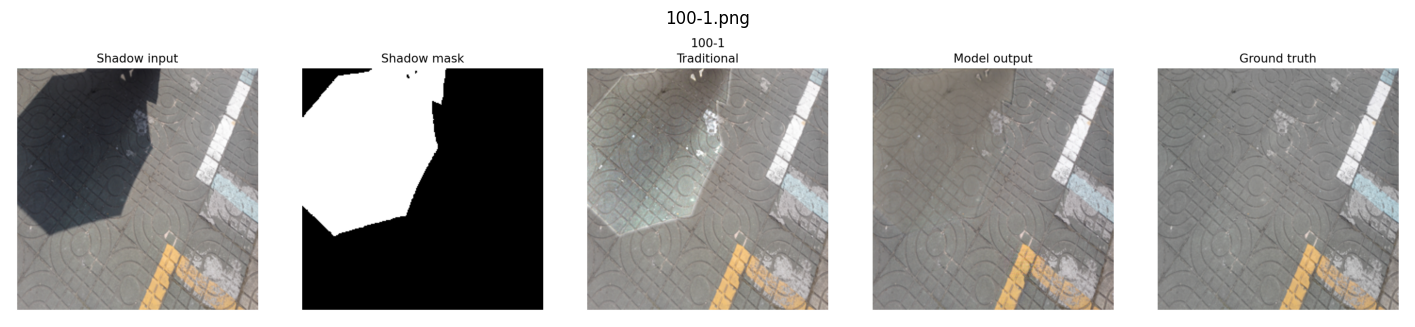

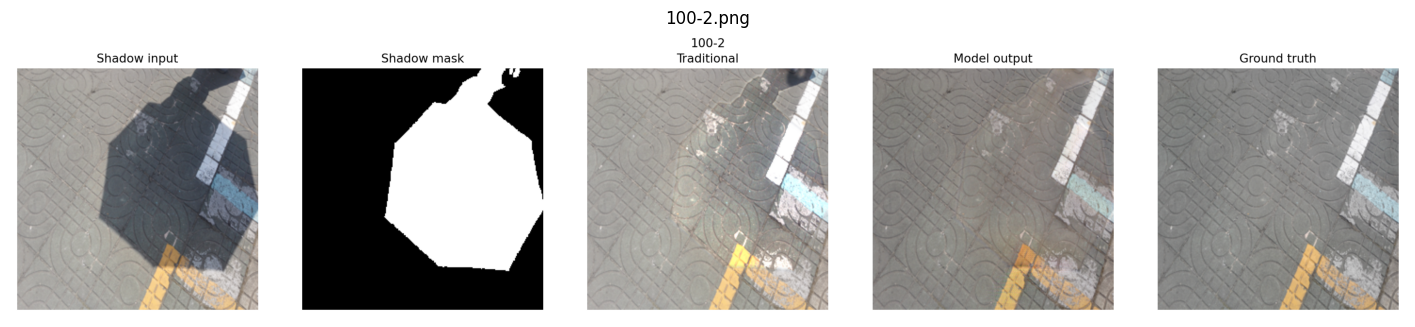

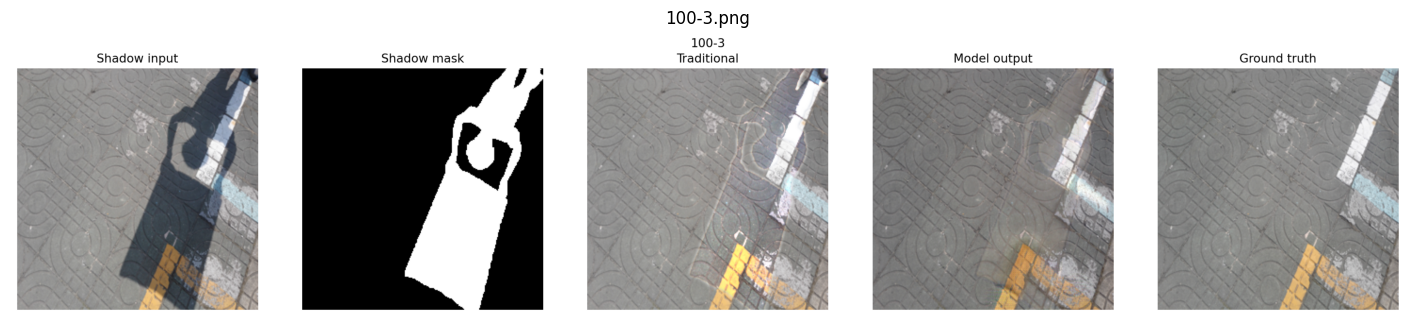

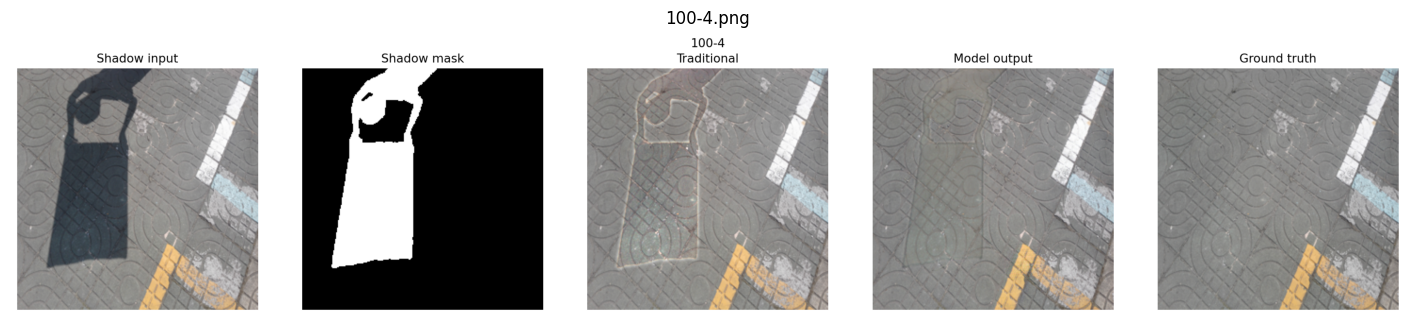

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

comparison_files = sorted(Path(BASELINE_EVAL, 'comparisons').glob('*.png'))[:4]
for path in comparison_files:
    image = Image.open(path)
    plt.figure(figsize=(18, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title(path.name)
    plt.show()


In [ ]:
from google.colab import files
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import subprocess

# Go to the project folder
%cd /content/shadow_removal_project

# Paths
CHECKPOINT = "/content/drive/MyDrive/shadow_removal_capstone/runs/baseline/best.pth"
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/shadow_removal_capstone/custom_outputs"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
uploaded = files.upload()
uploaded_name = next(iter(uploaded))
input_path = Path(uploaded_name).resolve()

subprocess.run(
    [
        "python",
        "inference.py",
        "--checkpoint",
        CHECKPOINT,
        "--input",
        str(input_path),
        "--output-dir",
        str(OUTPUT_DIR),
    ],
    check=True,
)

output_path = OUTPUT_DIR / f"{input_path.stem}.png"

if not output_path.exists():
    raise FileNotFoundError(
        f"Output was not found at {output_path}. "
        "Check the inference output above."
    )
input_image = Image.open(input_path).convert("RGB")
output_image = Image.open(output_path).convert("RGB")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(input_image)
plt.title("Original shadowed image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("Predicted shadow-free image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Saved output to:", output_path)
files.download(str(output_path))

/content/shadow_removal_project


Saving shadow.jpg to shadow (2).jpg


Saved output to: /content/drive/MyDrive/shadow_removal_capstone/custom_outputs/shadow (2).png


In [ ]:

!python train.py \
    --data-root "{DATA_ROOT}" \
    --output-dir "{BASELINE_RUN}_final" \
    --image-size 256 \
    --batch-size 8 \
    --epochs 50 \
    --learning-rate 1e-4 \
    --base-channels 32 \
    --output-mode direct \
    --shadow-weight 6 \
    --nonshadow-weight 1 \
    --edge-weight 0.10 \
    --perceptual-weight 0 \
    --amp

...
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth

Epoch 35/50
train_loss=0.04816 | val_loss=0.05072 | PSNR=31.510 | SSIM=0.9339 | lr=1.00e-04

Epoch 36/50
train_loss=0.04858 | val_loss=0.04969 | PSNR=31.694 | SSIM=0.9348 | lr=1.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth

Epoch 37/50
train_loss=0.04838 | val_loss=0.05085 | PSNR=31.201 | SSIM=0.9354 | lr=1.00e-04

Epoch 38/50
train_loss=0.04675 | val_loss=0.04999 | PSNR=31.721 | SSIM=0.9363 | lr=1.00e-04

Epoch 39/50
train_loss=0.04634 | val_loss=0.04919 | PSNR=31.922 | SSIM=0.9369 | lr=1.00e-04
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth

Epoch 40/50
train_loss=0.04700 | val_loss=0.05083 | PSNR=31.588 | SSIM=0.9363 | lr=1.00e-04

Epoch 41/50
train_loss=0.04719 | val_loss=0.04829 | PSNR=31.777 | SSIM=0.9370 | lr=1.00e-04
Saved new best checkpoint: /content/

In [ ]:
from google.colab import files
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import subprocess
%cd /content/shadow_removal_project

CHECKPOINT = "/content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth"
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/shadow_removal_capstone/custom_outputs"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
uploaded = files.upload()
uploaded_name = next(iter(uploaded))
input_path = Path(uploaded_name).resolve()
subprocess.run(
    [
        "python",
        "inference.py",
        "--checkpoint",
        CHECKPOINT,
        "--input",
        str(input_path),
        "--output-dir",
        str(OUTPUT_DIR),
    ],
    check=True,
)
output_path = OUTPUT_DIR / f"{input_path.stem}.png"

if not output_path.exists():
    raise FileNotFoundError(
        f"Output was not found at {output_path}. "
        "Check the inference output above."
    )
input_image = Image.open(input_path).convert("RGB")
output_image = Image.open(output_path).convert("RGB")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(input_image)
plt.title("Original shadowed image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("Predicted shadow-free image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Saved output to:", output_path)

# Download result
files.download(str(output_path))

/content/shadow_removal_project


Saving download.jpeg to download.jpeg


Saved output to: /content/drive/MyDrive/shadow_removal_capstone/custom_outputs/download.png


In [ ]:
!python train.py \
    --data-root "{DATA_ROOT}" \
    --output-dir "{BASELINE_RUN}_final" \
    --image-size 256 \
    --batch-size 8 \
    --epochs 50 \
    --learning-rate 1e-4 \
    --base-channels 32 \
    --output-mode residual \
    --shadow-weight 6 \
    --nonshadow-weight 1 \
    --edge-weight 0.10 \
    --perceptual-weight 0 \
    --amp

...
Epoch 33/50
train_loss=0.05580 | val_loss=0.06241 | PSNR=29.808 | SSIM=0.9347 | lr=5.00e-05

Epoch 34/50
train_loss=0.05569 | val_loss=0.06167 | PSNR=29.855 | SSIM=0.9367 | lr=2.50e-05

Epoch 35/50
train_loss=0.05334 | val_loss=0.05860 | PSNR=30.288 | SSIM=0.9370 | lr=2.50e-05
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth

Epoch 36/50
train_loss=0.05267 | val_loss=0.05945 | PSNR=30.208 | SSIM=0.9378 | lr=2.50e-05

Epoch 37/50
train_loss=0.05223 | val_loss=0.05896 | PSNR=30.215 | SSIM=0.9375 | lr=2.50e-05

Epoch 38/50
train_loss=0.05227 | val_loss=0.05886 | PSNR=30.178 | SSIM=0.9376 | lr=2.50e-05

Epoch 39/50
train_loss=0.05152 | val_loss=0.05879 | PSNR=30.297 | SSIM=0.9374 | lr=1.25e-05

Epoch 40/50
train_loss=0.05043 | val_loss=0.05755 | PSNR=30.391 | SSIM=0.9380 | lr=1.25e-05
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth

Epoch 41/50
train_loss=0.05019 | val_loss=0.05

/content/shadow_removal_project


Saving 101-4.png to 101-4.png


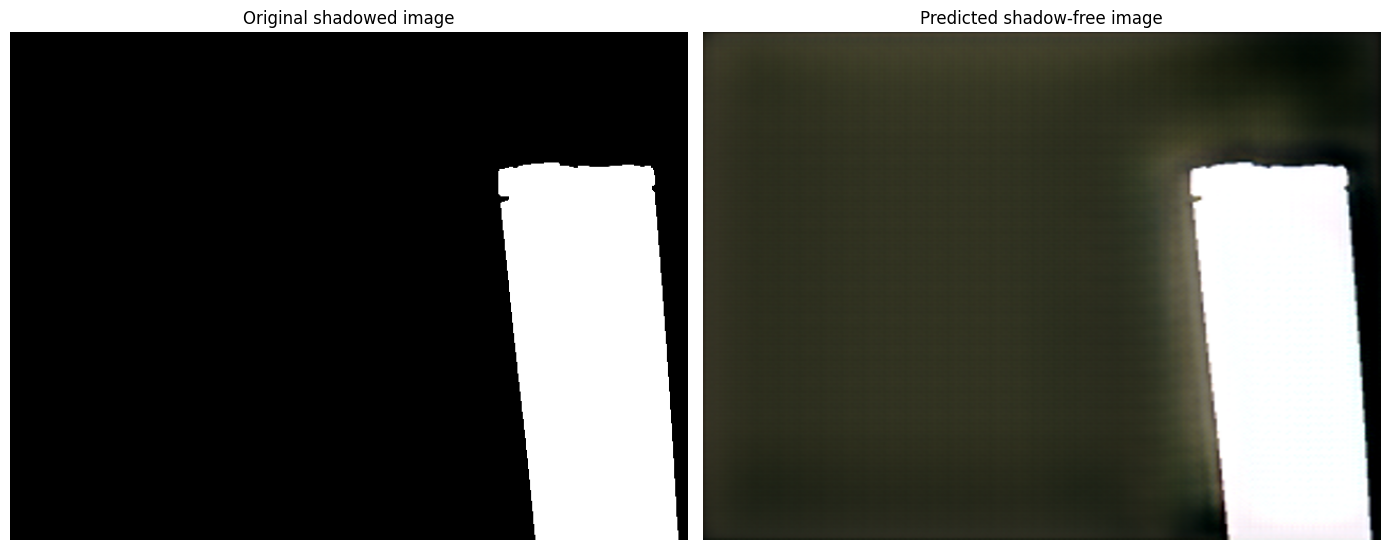

Saved output to: /content/drive/MyDrive/shadow_removal_capstone/custom_outputs/101-4.png


In [ ]:
from google.colab import files
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import subprocess
%cd /content/shadow_removal_project
CHECKPOINT = "/content/drive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth"
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/shadow_removal_capstone/custom_outputs"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
uploaded = files.upload()
uploaded_name = next(iter(uploaded))
input_path = Path(uploaded_name).resolve()
subprocess.run(
    [
        "python",
        "inference.py",
        "--checkpoint",
        CHECKPOINT,
        "--input",
        str(input_path),
        "--output-dir",
        str(OUTPUT_DIR),
    ],
    check=True,
)
output_path = OUTPUT_DIR / f"{input_path.stem}.png"

if not output_path.exists():
    raise FileNotFoundError(
        f"Output was not found at {output_path}. "
        "Check the inference output above."
    )
input_image = Image.open(input_path).convert("RGB")
output_image = Image.open(output_path).convert("RGB")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(input_image)
plt.title("Original shadowed image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("Predicted shadow-free image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Saved output to:", output_path)
files.download(str(output_path))

GRADIO UI

In [1]:
import os
import sys
import time
import subprocess
import tempfile
from pathlib import Path

import numpy as np
import cv2
from PIL import Image
import gradio as gr


PROJECT_DIR = Path(
    "/content/shadow_removal_project"
)

DRIVE_ROOT = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone"
)


CHECKPOINT = (
    DRIVE_ROOT
    / "runs"
    / "baseline_final"
    / "best.pth"
)

OUTPUT_DIR = (
    DRIVE_ROOT
    / "ui_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)
print("Checking ShadowFix ...")

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project folder not found:\n{PROJECT_DIR}"
    )

if not (PROJECT_DIR / "inference.py").exists():
    raise FileNotFoundError(
        f"inference.py not found:\n"
        f"{PROJECT_DIR / 'inference.py'}"
    )

if not CHECKPOINT.exists():
    raise FileNotFoundError(
        "Best RGB model checkpoint not found:\n"
        f"{CHECKPOINT}\n\n"
        "Make sure baseline_final/best.pth exists."
    )

print("Project found")
print("inference.py found")
print("BEST RGB checkpoint found")
print(f"Checkpoint: {CHECKPOINT}")
print("UI output folder ready")


def pil_rgb(x):
    if x is None:
        return None

    if isinstance(x, Image.Image):
        return x.convert("RGB")

    if isinstance(x, np.ndarray):

        if x.ndim == 2:
            return Image.fromarray(
                x.astype(np.uint8)
            ).convert("RGB")

        if x.shape[-1] == 4:
            x = x[:, :, :3]

        return Image.fromarray(
            x.astype(np.uint8)
        ).convert("RGB")

    return Image.open(x).convert("RGB")


def model_restore_rgb(image):
    image = pil_rgb(image)

    if image is None:
        raise gr.Error(
            "Please upload an image."
        )

    work_dir = Path(
        tempfile.mkdtemp(
            prefix="shadowfix_rgb_"
        )
    )

    input_path = (
        work_dir / "input.png"
    )

    output_dir = (
        work_dir / "output"
    )

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    image.save(
        str(input_path)
    )

    command = [
        sys.executable,
        "inference.py",

        "--checkpoint",
        str(CHECKPOINT),

        "--input",
        str(input_path),

        "--output-dir",
        str(output_dir),
    ]

    print("\n========================================")
    print("Running RGB-only ShadowFix model...")
    print("========================================")

    result = subprocess.run(
        command,
        cwd=str(PROJECT_DIR),
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:

        print(result.stderr)

        raise gr.Error(
            "Model inference failed.\n\n"
            + result.stderr[-4000:]
        )

    candidates = sorted(
        list(output_dir.glob("*.png"))
        + list(output_dir.glob("*.jpg"))
        + list(output_dir.glob("*.jpeg")),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    if not candidates:
        raise gr.Error(
            "The model finished but no output image was created."
        )

    output_path = candidates[0]

    print(
        "Model output:",
        output_path
    )

    return Image.open(
        output_path
    ).convert("RGB")


def automatic_shadow_mask(image):

    image = pil_rgb(image)

    rgb = np.array(
        image
    )

    # RGB -> LAB
    lab = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2LAB
    )

    L = (
        lab[:, :, 0]
        .astype(np.float32)
    )

    local_mean = cv2.GaussianBlur(
        L,
        (0, 0),
        sigmaX=35,
        sigmaY=35
    )
    darkness = (
        local_mean - L
    )

    mask = (
        darkness > 10
    ).astype(np.uint8) * 255



    small_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (7, 7)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        small_kernel
    )



    large_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (25, 25)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        large_kernel
    )

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    clean_mask = np.zeros_like(
        mask
    )

    min_area = 1500

    for i in range(
        1,
        num_labels
    ):

        area = stats[
            i,
            cv2.CC_STAT_AREA
        ]

        if area >= min_area:
            clean_mask[
                labels == i
            ] = 255

    return Image.fromarray(
        clean_mask,
        mode="L"
    )

def make_guided_mask(editor_data):

    if editor_data is None:
        raise gr.Error(
            "Please upload an image."
        )

    if not isinstance(
        editor_data,
        dict
    ):
        raise gr.Error(
            "Please use the Guided Mode image editor."
        )

    background = (
        editor_data.get("background")
    )

    layers = (
        editor_data.get("layers", [])
    )

    if background is None:
        raise gr.Error(
            "Please upload an image."
        )

    original = pil_rgb(
        background
    )

    width, height = (
        original.size
    )

    mask = None
    for layer in reversed(
        layers
    ):

        if layer is None:
            continue

        if isinstance(
            layer,
            Image.Image
        ):

            arr = np.array(
                layer
            )

        elif isinstance(
            layer,
            np.ndarray
        ):

            arr = layer

        else:
            continue
        if (
            arr.ndim == 3
            and arr.shape[2] == 4
        ):

            alpha = (
                arr[:, :, 3]
            )

            if np.max(alpha) > 0:

                mask = (
                    alpha.astype(
                        np.uint8
                    )
                )

                break
        elif arr.ndim == 3:

            rgb = (
                arr[:, :, :3]
            )

            gray = cv2.cvtColor(
                rgb.astype(
                    np.uint8
                ),
                cv2.COLOR_RGB2GRAY
            )

            if np.max(gray) > 0:

                mask = gray

                break

    if (
        mask is None
        or np.max(mask) == 0
    ):

        raise gr.Error(
            "No shadow was painted.\n\n"
            "Use the brush to paint over the shadow."
        )


    mask = cv2.resize(
        mask,
        (
            width,
            height
        ),
        interpolation=cv2.INTER_LINEAR
    )


    mask = np.where(
        mask > 20,
        255,
        0
    ).astype(
        np.uint8
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (5, 5)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    mask = cv2.GaussianBlur(
        mask,
        (9, 9),
        0
    )

    return (
        original,
        mask
    )


def guided_blend(
    original,
    restored,
    strength,
    mask
):

    original_np = np.asarray(
        original.convert("RGB")
    ).astype(
        np.float32
    )

    restored_np = np.asarray(
        restored.convert("RGB")
    ).astype(
        np.float32
    )

    if (
        original_np.shape[:2]
        != restored_np.shape[:2]
    ):

        restored_np = cv2.resize(
            restored_np,
            (
                original_np.shape[1],
                original_np.shape[0]
            ),
            interpolation=cv2.INTER_CUBIC
        )

    mask_float = (
        np.asarray(mask)
        .astype(np.float32)
        / 255.0
    )
    mask_float = cv2.GaussianBlur(
        mask_float,
        (15, 15),
        0
    )

    amount = np.clip(
        float(strength),
        0,
        100
    ) / 100.0

    alpha = (
        mask_float[..., None]
        * amount
    )

    output = (
        original_np * (1.0 - alpha)
        +
        restored_np * alpha
    )

    output = np.clip(
        output,
        0,
        255
    ).astype(
        np.uint8
    )

    return Image.fromarray(
        output,
        mode="RGB"
    )

def automatic_analysis(
    image,
    mask
):
    image_np = np.asarray(
        image.convert("RGB")
    )

    mask_np = np.asarray(
        mask.convert("L")
    )

    coverage = (
        np.count_nonzero(
            mask_np > 30
        )
        /
        mask_np.size
        * 100
    )

    if coverage < 5:
        severity = "Low"

    elif coverage < 15:
        severity = "Moderate"

    elif coverage < 35:
        severity = "High"

    else:
        severity = "Very High"

    return f"""
## AUTOMATIC ANALYSIS

| Metric | Result |
|---|---|
| Estimated Shadow Coverage | **{coverage:.1f}%** |
| Estimated Severity | **{severity}** |
| Model | **RGB Residual U-Net** |
| Model Input | **RGB image** |
| Shadow Mask Input | **Not required** |

### Automatic Processing

The RGB U-Net automatically predicts the shadow-free image.

The estimated mask shown beside the result is used for **analysis and visualization**; it is not required by the trained model.
"""

def automatic_restore(image):

    original = pil_rgb(
        image
    )

    if original is None:
        raise gr.Error(
            "Please upload an image."
        )
    restored = model_restore_rgb(
        original
    )
    estimated_mask = (
        automatic_shadow_mask(
            original
        )
    )

    analysis = automatic_analysis(
        original,
        estimated_mask
    )
    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    timestamp = int(
        time.time()
    )

    output_path = (
        OUTPUT_DIR
        /
        f"shadowfix_automatic_{timestamp}.png"
    )

    mask_path = (
        OUTPUT_DIR
        /
        f"shadowfix_auto_mask_{timestamp}.png"
    )

    restored.save(
        str(output_path)
    )

    estimated_mask.save(
        str(mask_path)
    )

    print(
        "Automatic result saved:",
        output_path
    )

    return (
        original,
        restored,
        (original, restored),
        estimated_mask,
        analysis,
        str(output_path)
    )

def guided_restore(
    editor_data,
    mode,
    strength
):

    original, mask = (
        make_guided_mask(
            editor_data
        )
    )

    if mode == "Natural":
        strength = 55

    elif mode == "Balanced":
        strength = 80

    elif mode == "Strong":
        strength = 100

    restored = model_restore_rgb(
        original
    )

    final = guided_blend(
        original,
        restored,
        strength,
        mask
    )
    mask_np = np.asarray(
        mask
    )

    coverage = (
        np.count_nonzero(
            mask_np > 30
        )
        /
        mask_np.size
        * 100
    )

    if coverage < 10:
        severity = "Low"

    elif coverage < 25:
        severity = "Moderate"

    elif coverage < 45:
        severity = "High"

    else:
        severity = "Very High"

    analysis = f"""
## 🎯 GUIDED  ANALYSIS

| Metric | Result |
|---|---|
| Guided Shadow Coverage | **{coverage:.1f}%** |
| Shadow Severity | **{severity}** |
| Restoration Mode | **{mode}** |
| Strength | **{strength:.0f}%** |
| Model | **RGB Residual U-Net** |
| Guidance | **User-Painted Shadow Region** |

### Recommendation

**{mode}** mode is being used.

- Increase strength if shadow remains.
- Reduce strength if the restored region becomes too strong.
- Refine the painted mask if the wrong region is affected.
"""

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    timestamp = int(
        time.time()
    )

    final_path = (
        OUTPUT_DIR
        /
        f"shadowfix_guided_{timestamp}.png"
    )

    mask_path = (
        OUTPUT_DIR
        /
        f"shadowfix_guided_mask_{timestamp}.png"
    )

    final.save(
        str(final_path)
    )

    Image.fromarray(
        mask.astype(np.uint8)
    ).save(
        str(mask_path)
    )

    print(
        "Guided result saved:",
        final_path
    )

    return (
        original,
        final,
        (original, final),
        Image.fromarray(
            mask
        ),
        analysis,
        str(final_path)
    )
def update_guided_strength(
    mode,
    current
):

    if mode == "Natural":
        return 55

    if mode == "Balanced":
        return 80

    if mode == "Strong":
        return 100
    return current

def assistant(question):

    if not question:
        return (
            "Please ask a question about ShadowFix."
        )

    q = question.lower()

    if (
        "remaining" in q
        or "left" in q
        or "visible" in q
    ):
        return """
### Restoration Assistant

A remaining shadow can happen when the shadow is outside the model's learned distribution or when the selected guided region does not cover the complete shadow.

For Guided Mode, refine the painted region and try **Strong** mode.
"""

    if "automatic" in q:
        return """
### Restoration Assistant

**Automatic Mode** sends the uploaded image directly to the trained RGB Residual U-Net.

No user-painted mask is required.
"""

    if "mask" in q:
        return """
### Restoration Assistant

In Guided Mode, the mask identifies the region where you want the restoration to be emphasized.

The current trained model is **RGB-only**, so the mask is not fed into the network.
"""

    if "natural" in q:
        return """
### Restoration Assistant

**Natural — 55%**

A conservative blend that keeps more of the original image.
"""

    if "balanced" in q:
        return """
### ✨ Restoration Assistant

**Balanced — 80%**

Recommended starting point for Guided Mode.
"""

    if "strong" in q:
        return """
### Restoration Assistant

**Strong — 100%**

Uses the maximum guided blending of the model's restoration inside the selected shadow region.
"""

    if (
        "model" in q
        or "unet" in q
    ):
        return """
### Restoration Assistant

ShadowFix uses an **RGB Residual U-Net**.

The network takes the shadowed RGB image and predicts a restoration. Guided Mode then lets the user control where that restoration is emphasized.
"""

    if "slider" in q:
        return """
### Restoration Assistant

The Guided Mode slider controls how strongly the neural-network restoration is blended into the user-selected shadow region.

Try **80%** first.
"""

    return """
### Restoration Assistant

I can explain:

- Automatic Mode
- Guided Mode
- The shadow mask
- Natural / Balanced / Strong
- The restoration slider
- How the RGB Residual U-Net works
"""

with gr.Blocks(
    title="ShadowFix "
) as app:

    gr.Markdown(
        """
# ✨ ShadowFix
### Intelligent Shadow Removal & Image Restoration

**Automatic detection • Guided restoration • Before/After comparison**
"""
    )

    gr.Markdown(
        """
### Model
**RGB Residual U-Net**

The final interface uses the best RGB-only checkpoint from the capstone training pipeline.
"""
    )

    with gr.Tabs():

        with gr.Tab("🤖 Automatic Mode"):

            gr.Markdown(
                """
## 🤖 Automatic Shadow Removal

Upload your image and let ShadowFix automatically restore it.

**No painting or manual mask is required.**
"""
            )

            auto_input = gr.Image(
                type="pil",
                label="Upload Shadowed Image",
                height=450
            )

            auto_button = gr.Button(
                "AUTOMATICALLY REMOVE SHADOW",
                variant="primary",
                size="lg"
            )

            with gr.Row():

                auto_original = gr.Image(
                    label="ORIGINAL",
                    type="pil"
                )

                auto_restored = gr.Image(
                    label="RESTORED",
                    type="pil"
                )

            auto_comparison = gr.ImageSlider(
                label="🔄 BEFORE / AFTER",
                type="pil"
            )

            with gr.Row():

                auto_mask = gr.Image(
                    label="ESTIMATED SHADOW MAP",
                    type="pil"
                )

                auto_analysis = gr.Markdown()

            auto_download = gr.DownloadButton(
                label="⬇Download Automatic Result"
            )

            auto_button.click(
                automatic_restore,
                inputs=[
                    auto_input
                ],
                outputs=[
                    auto_original,
                    auto_restored,
                    auto_comparison,
                    auto_mask,
                    auto_analysis,
                    auto_download
                ]
            )
        with gr.Tab("Guided Mode"):

            gr.Markdown(
                """
## 🎯 Guided Shadow Removal

**1. Upload your image**
**2. Paint over the shadow**
**3. Use the eraser to fix mistakes**
**4. Select Natural / Balanced / Strong / Custom**
**5. Click RESTORE SHADOW**
"""
            )

            editor = gr.ImageEditor(
                label="Paint Over the Shadow",
                type="pil",
                image_mode="RGBA",
                height=500
            )

            gr.Markdown(
                """
 **Brush:** paint over the complete shadow
 **Eraser:** remove incorrect areas
 **Tip:** cover the whole shadow, including soft edges.
"""
            )

            guided_mode = gr.Radio(
                [
                    "Natural",
                    "Balanced",
                    "Strong",
                    "Custom"
                ],
                value="Balanced",
                label="Restoration Mode"
            )

            guided_strength = gr.Slider(
                minimum=0,
                maximum=100,
                value=80,
                step=5,
                label="Shadow Removal Strength"
            )

            guided_mode.change(
                update_guided_strength,
                inputs=[
                    guided_mode,
                    guided_strength
                ],
                outputs=[
                    guided_strength
                ]
            )

            guided_button = gr.Button(
                "✨ RESTORE SHADOW",
                variant="primary",
                size="lg"
            )

            with gr.Row():

                guided_original = gr.Image(
                    label="ORIGINAL",
                    type="pil"
                )

                guided_restored = gr.Image(
                    label="RESTORED",
                    type="pil"
                )

            guided_comparison = gr.ImageSlider(
                label="BEFORE / AFTER",
                type="pil"
            )

            with gr.Row():

                guided_mask_output = gr.Image(
                   label="GUIDED SHADOW MASK",
                   type="pil"
                )

                guided_analysis = gr.Markdown()

            guided_download = gr.DownloadButton(
                label="Download Guided Result"
            )

            guided_button.click(
                guided_restore,
                inputs=[
                    editor,
                    guided_mode,
                    guided_strength
                ],
                outputs=[
                    guided_original,
                    guided_restored,
                    guided_comparison,
                    guided_mask_output,
                    guided_analysis,
                    guided_download
                ]
            )

        with gr.Tab("Restoration Assistant"):

            gr.Markdown(
                """
# Restoration Assistant

Ask questions about the restoration process, model, mask, or settings.
"""
            )

            question = gr.Textbox(
                label="Ask a question",
                placeholder="How does Automatic Mode work?",
                lines=3
            )

            ask_button = gr.Button(
                "Ask Assistant",
                variant="primary"
            )

            answer = gr.Markdown()

            ask_button.click(
                assistant,
                inputs=[
                    question
                ],
                outputs=[
                    answer
                ]
            )

            gr.Examples(
                examples=[
                    [
                        "How does Automatic Mode work?"
                    ],
                    [
                        "How does Guided Mode work?"
                    ],
                    [
                        "Why is some shadow remaining?"
                    ],
                    [
                        "What does Strong mode do?"
                    ],
                    [
                        "How does the U-Net work?"
                    ]
                ],
                inputs=[
                    question
                ]
            )

    gr.Markdown(
        """
---


"""
    )

print(
    "\n🚀 Starting ShadowFix ..."
)

print(
    "Checkpoint:",
    CHECKPOINT
)

app.launch(
    share=True,
    debug=True,
    show_error=True,
    allowed_paths=[
        str(OUTPUT_DIR)
    ]
)

Checking ShadowFix ...


FileNotFoundError: Project folder not found:
/content/shadow_removal_project

In [54]:
FINAL_RUN = f"{DRIVE_ROOT}/runs/baseline_100"
print(FINAL_RUN)

/content/mydrive/MyDrive/shadow_removal_capstone/runs/baseline_100


In [ ]:

!python train.py \
    --data-root "{DATA_ROOT}" \
    --output-dir "{FINAL_RUN}" \
    --image-size 256 \
    --batch-size 8 \
    --epochs 100 \
    --learning-rate 1e-4 \
    --base-channels 32 \
    --output-mode residual \
    --shadow-weight 6 \
    --nonshadow-weight 1 \
    --edge-weight 0.10 \
    --perceptual-weight 0 \
    --resume "{BASELINE_RUN}_final/last.pth" \
    --amp

...
train_loss=0.04622 | val_loss=0.05543 | PSNR=30.821 | SSIM=0.9404 | lr=6.25e-06

Epoch 64/100
train_loss=0.04602 | val_loss=0.05552 | PSNR=30.806 | SSIM=0.9404 | lr=6.25e-06

Epoch 65/100
train_loss=0.04598 | val_loss=0.05529 | PSNR=30.787 | SSIM=0.9407 | lr=6.25e-06
Saved new best checkpoint: /content/drive/MyDrive/shadow_removal_capstone/runs/baseline_100/best.pth

Epoch 66/100
train_loss=0.04599 | val_loss=0.05542 | PSNR=30.818 | SSIM=0.9408 | lr=6.25e-06

Epoch 67/100
train_loss=0.04591 | val_loss=0.05565 | PSNR=30.865 | SSIM=0.9403 | lr=6.25e-06

Epoch 68/100
train_loss=0.04577 | val_loss=0.05542 | PSNR=30.866 | SSIM=0.9408 | lr=6.25e-06

Epoch 69/100
train_loss=0.04562 | val_loss=0.05526 | PSNR=30.838 | SSIM=0.9407 | lr=6.25e-06

Epoch 70/100
train_loss=0.04559 | val_loss=0.05526 | PSNR=30.827 | SSIM=0.9405 | lr=6.25e-06

Epoch 71/100
train_loss=0.04554 | val_loss=0.05532 | PSNR=30.864 | SSIM=0.9408 | lr=6.25e-06

Epoch 72/100
train_loss=0.04545 | val_loss=0.05547 | PSNR=30.8

In [55]:
from pathlib import Path

FINAL_RUN = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone/runs/baseline_100"
)

print("Folder exists:", FINAL_RUN.exists())

if FINAL_RUN.exists():
    for p in sorted(FINAL_RUN.iterdir()):
        print(
            p.name,
            f"{p.stat().st_size / (1024**3):.2f} GB"
        )

Folder exists: True
best.pth 0.09 GB
epoch_051.pth 0.09 GB
epoch_052.pth 0.09 GB
epoch_053.pth 0.09 GB
epoch_054.pth 0.09 GB
epoch_055.pth 0.09 GB
epoch_056.pth 0.09 GB
epoch_057.pth 0.09 GB
epoch_058.pth 0.09 GB
epoch_059.pth 0.09 GB
epoch_060.pth 0.09 GB
epoch_061.pth 0.09 GB
epoch_062.pth 0.09 GB
epoch_063.pth 0.09 GB
epoch_064.pth 0.09 GB
epoch_065.pth 0.09 GB
epoch_066.pth 0.09 GB
epoch_067.pth 0.09 GB
epoch_068.pth 0.09 GB
epoch_069.pth 0.09 GB
epoch_070.pth 0.09 GB
epoch_071.pth 0.09 GB
epoch_072.pth 0.09 GB
epoch_073.pth 0.09 GB
epoch_074.pth 0.09 GB
epoch_075.pth 0.09 GB
epoch_076.pth 0.09 GB
epoch_077.pth 0.09 GB
epoch_078.pth 0.09 GB
epoch_079.pth 0.09 GB
epoch_080.pth 0.09 GB
epoch_081.pth 0.09 GB
epoch_082.pth 0.09 GB
epoch_083.pth 0.09 GB
last.pth 0.09 GB
training_history.csv 0.00 GB
training_history.png 0.00 GB


In [56]:
import os

print("Drive exists:", os.path.exists("/content/drive"))
print("MyDrive exists:", os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("\nMyDrive contents:")
    print(os.listdir("/content/drive/MyDrive")[:50])

Drive exists: True
MyDrive exists: True

MyDrive contents:
['shadow_removal_capstone']


In [ ]:
from google.colab import files
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import subprocess
%cd /content/shadow_removal_project
CHECKPOINT = "/content/mydrive/MyDrive/shadow_removal_capstone/runs/baseline_100/best.pth"
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/shadow_removal_capstone/custom_outputs"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
uploaded = files.upload()
uploaded_name = next(iter(uploaded))
input_path = Path(uploaded_name).resolve()
subprocess.run(
    [
        "python",
        "inference.py",
        "--checkpoint",
        CHECKPOINT,
        "--input",
        str(input_path),
        "--output-dir",
        str(OUTPUT_DIR),
    ],
    check=True,
)
output_path = OUTPUT_DIR / f"{input_path.stem}.png"

if not output_path.exists():
    raise FileNotFoundError(
        f"Output was not found at {output_path}. "
        "Check the inference output above."
    )
input_image = Image.open(input_path).convert("RGB")
output_image = Image.open(output_path).convert("RGB")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(input_image)
plt.title("Original shadowed image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("Predicted shadow-free image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Saved output to:", output_path)

# Download result
files.download(str(output_path))

/content/shadow_removal_project


Saving 100-5.png to 100-5.png


Saved output to: /content/drive/MyDrive/shadow_removal_capstone/custom_outputs/100-5.png


In [62]:


import pandas as pd
from pathlib import Path

BASELINE_EVAL = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone/"
    "evaluation/baseline"
)

MASK_EVAL = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone/"
    "evaluation/mask_guided"
)

FINAL_EVAL = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone/"
    "evaluation/baseline_100"
)

baseline_metrics = pd.read_csv(
    BASELINE_EVAL / "metrics_summary.csv"
)

mask_metrics = pd.read_csv(
    MASK_EVAL / "metrics_summary.csv"
)

final_metrics = pd.read_csv(
    FINAL_EVAL / "metrics_summary.csv"
)

baseline_row = baseline_metrics[
    baseline_metrics["method"] == "U-Net model"
].iloc[0]

mask_row = mask_metrics[
    mask_metrics["method"] == "U-Net model"
].iloc[0]

final_row = final_metrics[
    final_metrics["method"] == "U-Net model"
].iloc[0]

traditional_row = baseline_metrics[
    baseline_metrics["method"] == "Traditional correction"
].iloc[0]

input_row = baseline_metrics[
    baseline_metrics["method"] == "Shadow input"
].iloc[0]

comparison = pd.DataFrame({
    "Method": [
        "Shadow Input",
        "Traditional Correction",
        "RGB U-Net Baseline",
        "RGB U-Net — 100 Epochs",
        "Mask-Guided U-Net"
    ],

    "PSNR": [
        input_row["psnr"],
        traditional_row["psnr"],
        baseline_row["psnr"],
        final_row["psnr"],
        mask_row["psnr"]
    ],

    "SSIM": [
        input_row["ssim"],
        traditional_row["ssim"],
        baseline_row["ssim"],
        final_row["ssim"],
        mask_row["ssim"]
    ],

    "Shadow PSNR": [
        input_row["shadow_psnr"],
        traditional_row["shadow_psnr"],
        baseline_row["shadow_psnr"],
        final_row["shadow_psnr"],
        mask_row["shadow_psnr"]
    ],

    "Non-Shadow PSNR": [
        input_row["nonshadow_psnr"],
        traditional_row["nonshadow_psnr"],
        baseline_row["nonshadow_psnr"],
        final_row["nonshadow_psnr"],
        mask_row["nonshadow_psnr"]
    ]
})

comparison = comparison.round(4)

display(comparison)

In [63]:


from pathlib import Path
import subprocess
import sys

PROJECT_DIR = Path("/content/shadow_removal_project")
DATA_ROOT = "/content/data"

DRIVE_ROOT = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone"
)

RUNS_ROOT = DRIVE_ROOT / "runs"
EVAL_ROOT = DRIVE_ROOT / "evaluation"

models_to_evaluate = {
    "baseline_final": RUNS_ROOT / "baseline_final" / "best.pth",
    "baseline_100": RUNS_ROOT / "baseline_100" / "best.pth",
}

for model_name, checkpoint in models_to_evaluate.items():

    eval_dir = EVAL_ROOT / model_name
    metrics_file = eval_dir / "metrics_summary.csv"

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)
    if metrics_file.exists():
        print("Already evaluated:")
        print(metrics_file)
        continue

    if not checkpoint.exists():
        print("Checkpoint missing:")
        print(checkpoint)
        continue

    eval_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    print("Checkpoint:")
    print(checkpoint)

    result = subprocess.run(
        [
            sys.executable,
            "evaluate.py",

            "--data-root",
            DATA_ROOT,

            "--checkpoint",
            str(checkpoint),

            "--output-dir",
            str(eval_dir),

            "--batch-size",
            "8",

            "--num-visuals",
            "20",

            "--include-traditional",
        ],
        cwd=str(PROJECT_DIR),
        text=True,
        capture_output=True,
    )

    print(result.stdout)

    if result.returncode != 0:
        print("Evaluation error:")
        print(result.stderr)
    else:
        print("Evaluation complete")
        print(metrics_file)


MODEL: baseline_final
Checkpoint:
/content/mydrive/MyDrive/shadow_removal_capstone/runs/baseline_final/best.pth
Test records: 540 triplets (540 with masks)
Device: cuda; image size: 256

Evaluation summary
----------------------------------------------------------------------------------
Method                           PSNR       SSIM     Shadow PSNR      Non-shadow
Shadow input                   20.559     0.9100          13.414          26.477
U-Net model                    26.589     0.9268          25.062          27.223
Traditional correction         24.700     0.9338          21.516          25.942

Saved evaluation files to: /content/mydrive/MyDrive/shadow_removal_capstone/evaluation/baseline_final

Evaluation complete
/content/mydrive/MyDrive/shadow_removal_capstone/evaluation/baseline_final/metrics_summary.csv

MODEL: baseline_100
Already evaluated:
/content/mydrive/MyDrive/shadow_removal_capstone/evaluation/baseline_100/metrics_summary.csv


In [64]:

import pandas as pd
from pathlib import Path

DRIVE_ROOT = Path(
    "/content/mydrive/MyDrive/shadow_removal_capstone"
)

EVAL_ROOT = DRIVE_ROOT / "evaluation"

evaluation_files = {
    "RGB Baseline":
        EVAL_ROOT / "baseline" / "metrics_summary.csv",

    "Mask-Guided U-Net":
        EVAL_ROOT / "mask_guided" / "metrics_summary.csv",

    "RGB Residual (50 epochs)":
        EVAL_ROOT / "baseline_final" / "metrics_summary.csv",

    "RGB Residual (continued)":
        EVAL_ROOT / "baseline_100" / "metrics_summary.csv",
}

rows = []

for model_name, csv_path in evaluation_files.items():

    if not csv_path.exists():
        print("Missing:", csv_path)
        continue

    df = pd.read_csv(csv_path)
    model_row = df[
        df["method"].str.lower() == "u-net model"
    ]

    if len(model_row) == 0:
        print(
            f" U-Net row not found for {model_name}"
        )
        continue

    model_row = model_row.iloc[0]

    rows.append({
        "Model": model_name,
        "PSNR": model_row["psnr"],
        "SSIM": model_row["ssim"],
        "Shadow PSNR": model_row["shadow_psnr"],
        "Non-Shadow PSNR": model_row["nonshadow_psnr"],
    })

comparison_df = pd.DataFrame(rows)
comparison_df = comparison_df.sort_values(
    "PSNR",
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
display(
    comparison_df.style.format({
        "PSNR": "{:.3f}",
        "SSIM": "{:.4f}",
        "Shadow PSNR": "{:.3f}",
        "Non-Shadow PSNR": "{:.3f}",
    })
)
GRAPH_DIR = DRIVE_ROOT / "presentation_graphs"
GRAPH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

comparison_df.to_csv(
    GRAPH_DIR / "model_comparison.csv",
    index=False
)

print(
    "\nSaved:",
    GRAPH_DIR / "model_comparison.csv"
)


FINAL MODEL COMPARISON


,Model,PSNR,SSIM,Shadow PSNR,Non-Shadow PSNR
0,Mask-Guided U-Net,30.189,0.9514,26.303,31.887
1,RGB Baseline,27.176,0.9324,24.097,28.549
2,RGB Residual (50 epochs),26.589,0.9268,25.062,27.223
3,RGB Residual (continued),26.428,0.9268,25.027,27.036



Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/model_comparison.csv


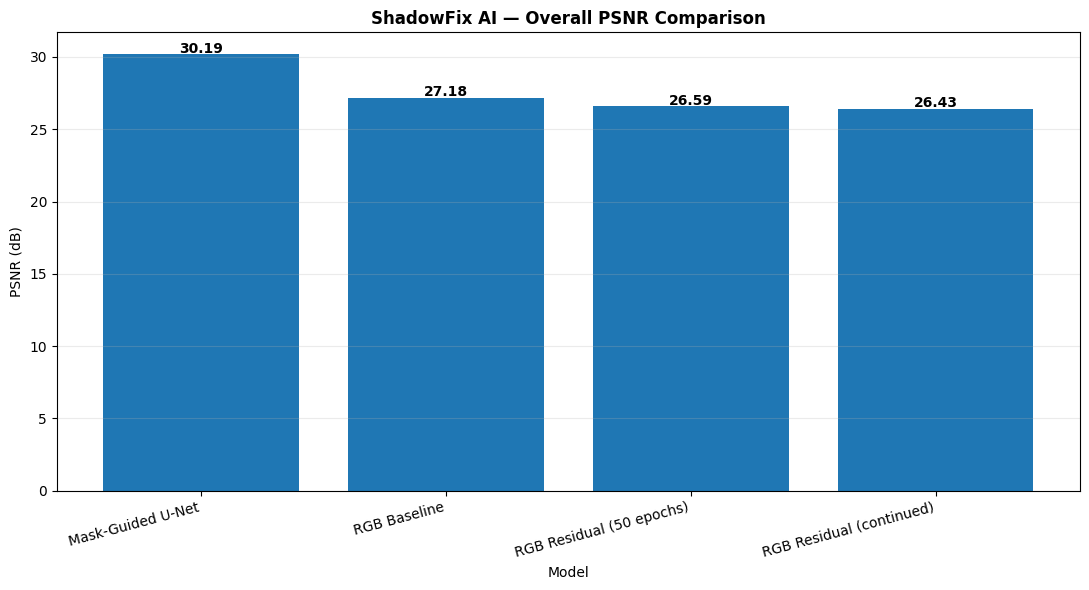

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/01_overall_psnr_comparison.png


In [65]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["PSNR"]
)

plt.ylabel("PSNR (dB)")
plt.xlabel("Model")
plt.title(
    "ShadowFix AI — Overall PSNR Comparison",
    fontweight="bold"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)
for bar, value in zip(
    bars,
    comparison_df["PSNR"]
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.10,
        f"{value:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "01_overall_psnr_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

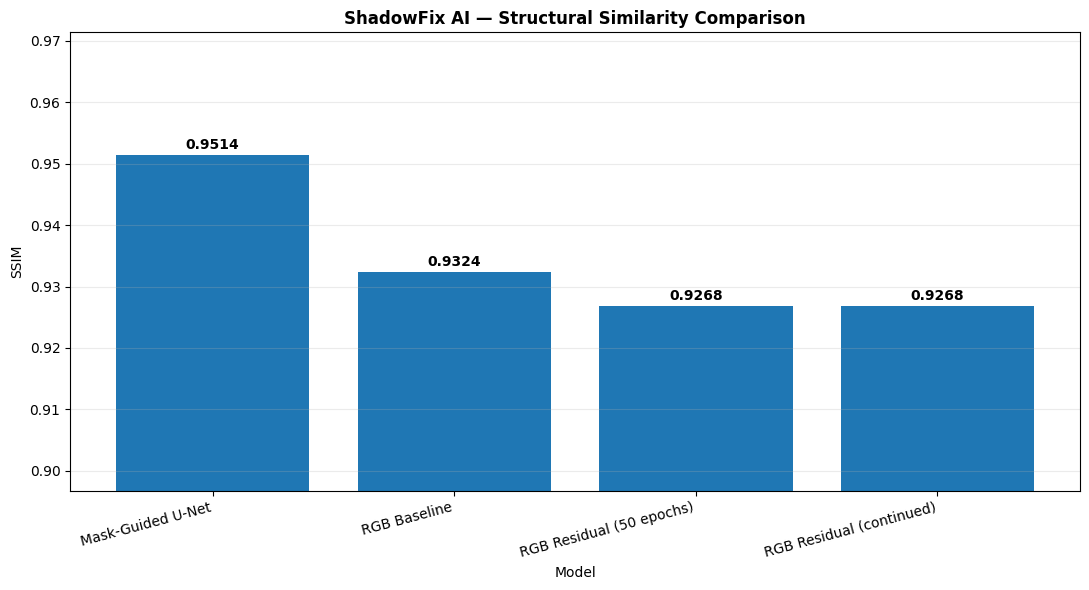

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/02_ssim_comparison.png


In [66]:

plt.figure(figsize=(11, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["SSIM"]
)

plt.ylabel("SSIM")
plt.xlabel("Model")

plt.title(
    "ShadowFix AI — Structural Similarity Comparison",
    fontweight="bold"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.ylim(
    max(0, comparison_df["SSIM"].min() - 0.03),
    min(1.0, comparison_df["SSIM"].max() + 0.02)
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    comparison_df["SSIM"]
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.001,
        f"{value:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "02_ssim_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

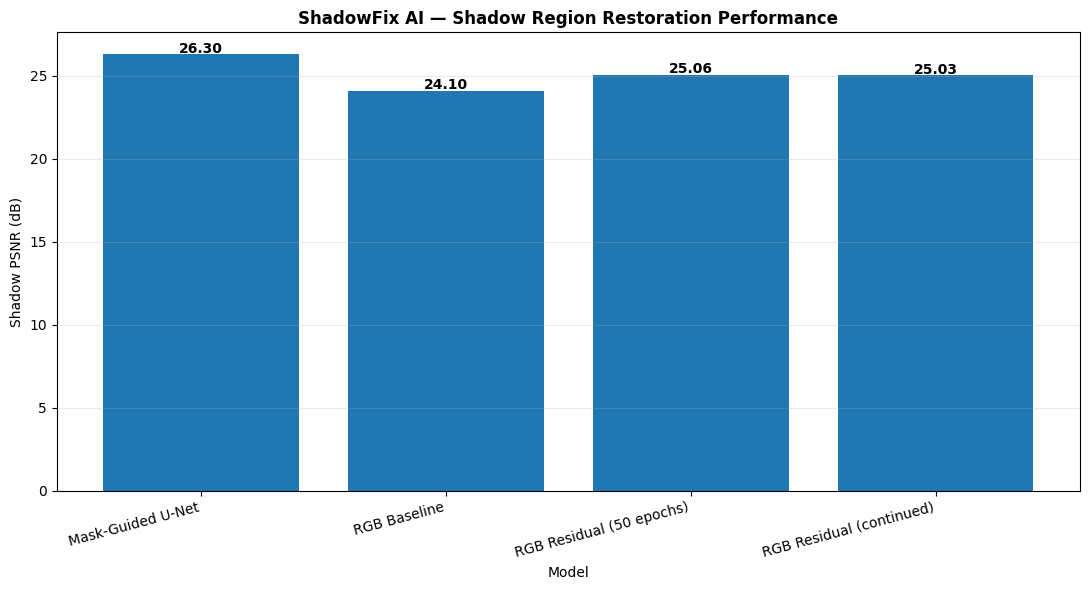

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/03_shadow_psnr_comparison.png


In [67]:


plt.figure(figsize=(11, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Shadow PSNR"]
)

plt.ylabel("Shadow PSNR (dB)")
plt.xlabel("Model")

plt.title(
    "ShadowFix AI — Shadow Region Restoration Performance",
    fontweight="bold"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    comparison_df["Shadow PSNR"]
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.10,
        f"{value:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "03_shadow_psnr_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

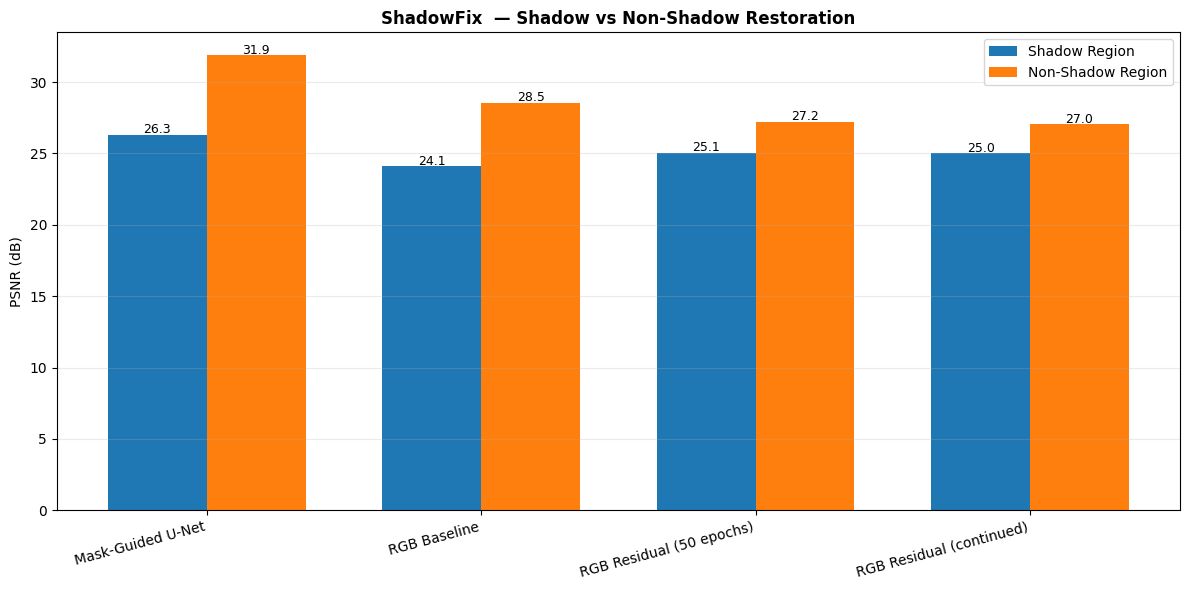

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/04_shadow_vs_nonshadow.png


In [69]:

import numpy as np

models = comparison_df["Model"].tolist()

shadow = comparison_df[
    "Shadow PSNR"
].to_numpy()

nonshadow = comparison_df[
    "Non-Shadow PSNR"
].to_numpy()

x = np.arange(len(models))

width = 0.36

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width/2,
    shadow,
    width,
    label="Shadow Region"
)

bars2 = plt.bar(
    x + width/2,
    nonshadow,
    width,
    label="Non-Shadow Region"
)

plt.ylabel("PSNR (dB)")

plt.title(
    "ShadowFix  — Shadow vs Non-Shadow Restoration",
    fontweight="bold"
)

plt.xticks(
    x,
    models,
    rotation=15,
    ha="right"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.25
)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.10,
            f"{value:.1f}",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "04_shadow_vs_nonshadow.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

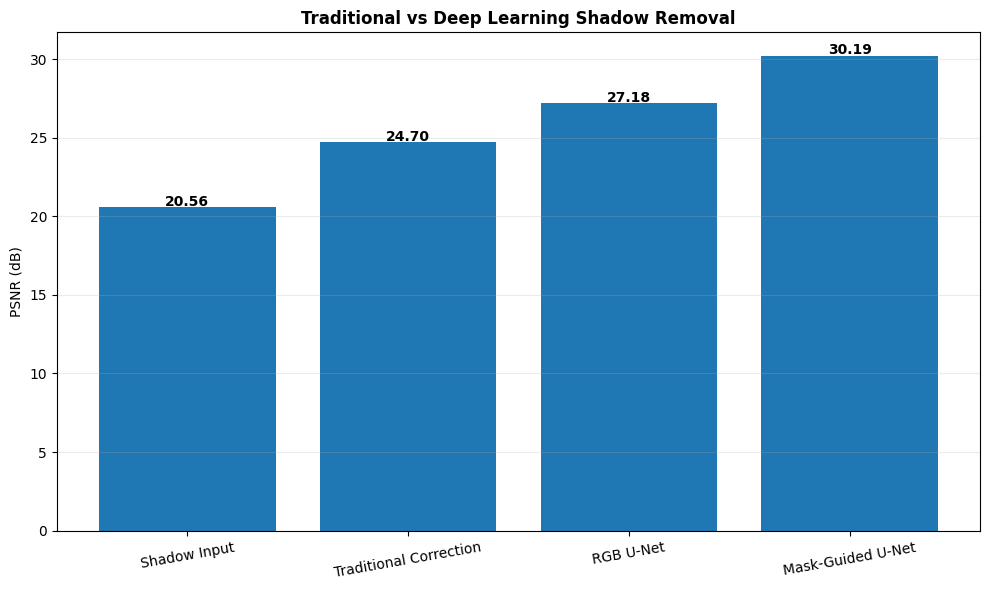

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/05_traditional_vs_deep_learning.png


In [70]:


baseline_csv = (
    EVAL_ROOT /
    "baseline" /
    "metrics_summary.csv"
)

mask_csv = (
    EVAL_ROOT /
    "mask_guided" /
    "metrics_summary.csv"
)

baseline_df = pd.read_csv(
    baseline_csv
)

mask_df = pd.read_csv(
    mask_csv
)

shadow_input = baseline_df[
    baseline_df["method"] == "Shadow input"
].iloc[0]

traditional = baseline_df[
    baseline_df["method"] == "Traditional correction"
].iloc[0]

rgb_model = baseline_df[
    baseline_df["method"] == "U-Net model"
].iloc[0]

mask_model = mask_df[
    mask_df["method"] == "U-Net model"
].iloc[0]

method_df = pd.DataFrame({
    "Method": [
        "Shadow Input",
        "Traditional Correction",
        "RGB U-Net",
        "Mask-Guided U-Net",
    ],
    "PSNR": [
        shadow_input["psnr"],
        traditional["psnr"],
        rgb_model["psnr"],
        mask_model["psnr"],
    ],
})

plt.figure(figsize=(10, 6))

bars = plt.bar(
    method_df["Method"],
    method_df["PSNR"]
)

plt.ylabel("PSNR (dB)")

plt.title(
    "Traditional vs Deep Learning Shadow Removal",
    fontweight="bold"
)

plt.xticks(
    rotation=10
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    method_df["PSNR"]
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.10,
        f"{value:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "05_traditional_vs_deep_learning.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

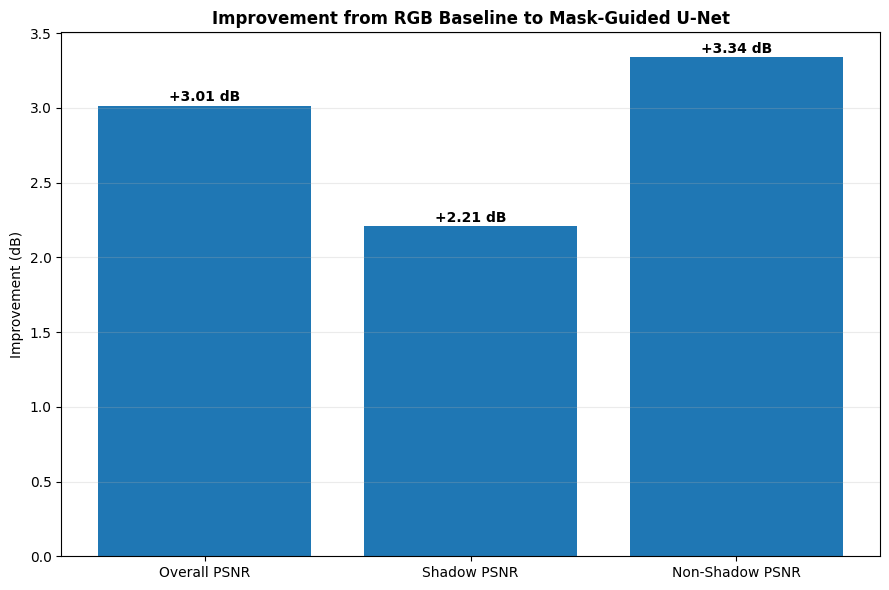

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/06_mask_guided_improvement.png


In [71]:


rgb = rgb_model
mask = mask_model

improvements = pd.DataFrame({
    "Metric": [
        "Overall PSNR",
        "Shadow PSNR",
        "Non-Shadow PSNR",
    ],
    "Improvement": [
        mask["psnr"] -
        rgb["psnr"],

        mask["shadow_psnr"] -
        rgb["shadow_psnr"],

        mask["nonshadow_psnr"] -
        rgb["nonshadow_psnr"],
    ],
})

plt.figure(figsize=(9, 6))

bars = plt.bar(
    improvements["Metric"],
    improvements["Improvement"]
)

plt.ylabel("Improvement (dB)")

plt.title(
    "Improvement from RGB Baseline to Mask-Guided U-Net",
    fontweight="bold"
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    improvements["Improvement"]
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.03,
        f"+{value:.2f} dB",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "06_mask_guided_improvement.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

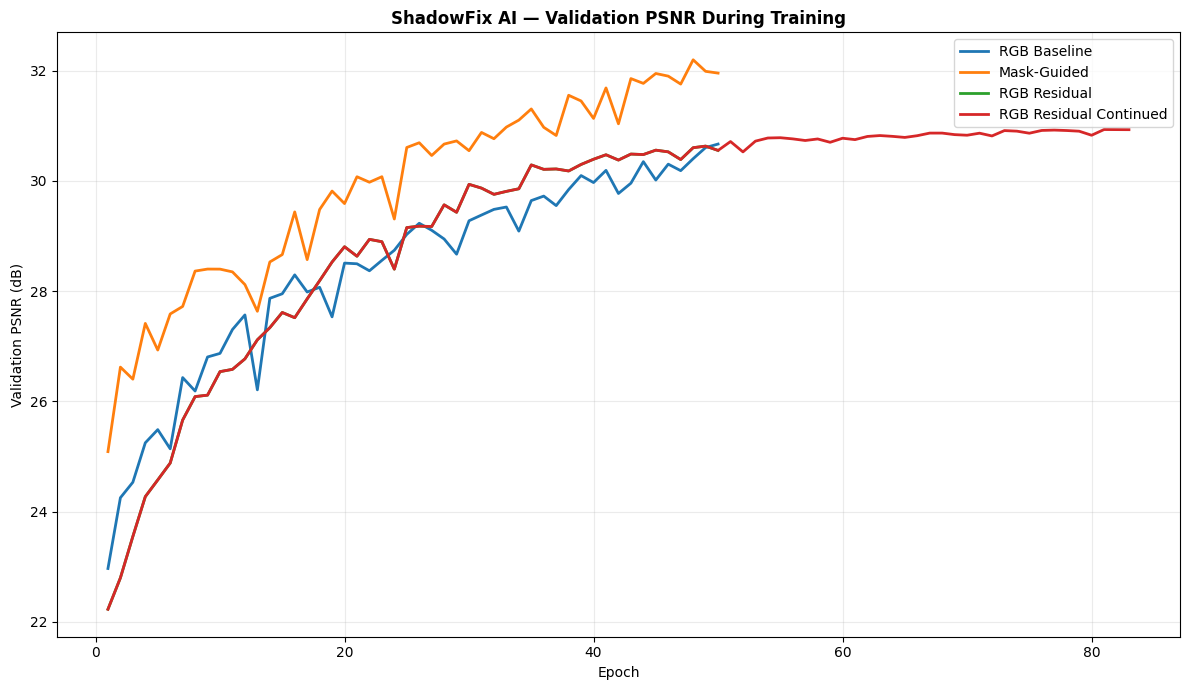

Saved: /content/mydrive/MyDrive/shadow_removal_capstone/presentation_graphs/07_training_psnr_curves.png


In [72]:

import pandas as pd
import matplotlib.pyplot as plt

RUNS_ROOT = (
    DRIVE_ROOT /
    "runs"
)

histories = {
    "RGB Baseline":
        RUNS_ROOT /
        "baseline" /
        "training_history.csv",

    "Mask-Guided":
        RUNS_ROOT /
        "mask_guided" /
        "training_history.csv",

    "RGB Residual":
        RUNS_ROOT /
        "baseline_final" /
        "training_history.csv",

    "RGB Residual Continued":
        RUNS_ROOT /
        "baseline_100" /
        "training_history.csv",
}

plt.figure(figsize=(12, 7))

for model_name, history_path in histories.items():

    if not history_path.exists():
        print(
            "Skipping missing:",
            history_path
        )
        continue

    df = pd.read_csv(
        history_path
    )
    epoch_col = next(
        (
            c for c in df.columns
            if c.lower() == "epoch"
        ),
        None
    )
    psnr_col = next(
        (
            c for c in df.columns
            if "psnr" in c.lower()
        ),
        None
    )

    if epoch_col is None:
        x = range(
            1,
            len(df) + 1
        )
    else:
        x = df[epoch_col]

    if psnr_col is None:
        print(
            "No PSNR column in:",
            history_path
        )
        print(
            "Columns:",
            df.columns.tolist()
        )
        continue

    plt.plot(
        x,
        df[psnr_col],
        label=model_name,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Validation PSNR (dB)")

plt.title(
    "ShadowFix AI — Validation PSNR During Training",
    fontweight="bold"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

save_path = (
    GRAPH_DIR /
    "07_training_psnr_curves.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)